✓ Loaded image: boss.png (627x454 px)


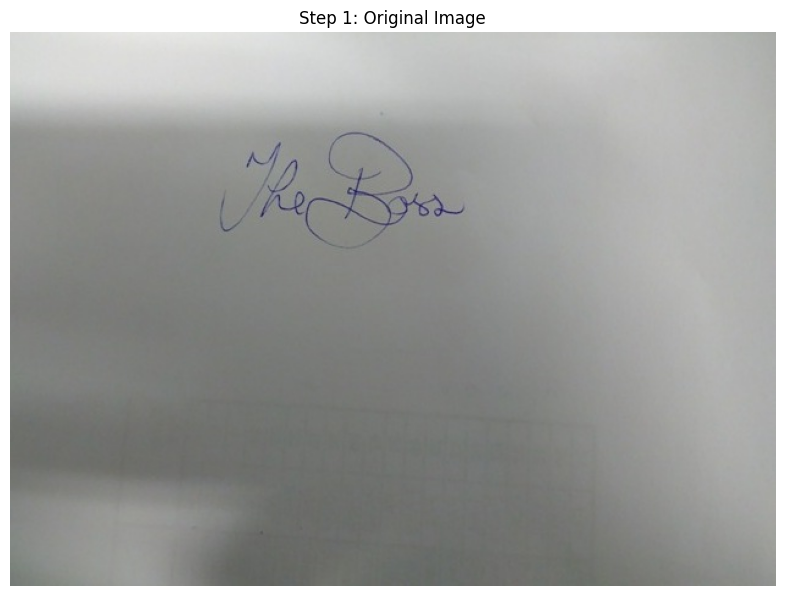

✓ Converted to grayscale and applied Gaussian blur (5x5)
✓ Adaptive Threshold applied (blockSize=31, C=2)
  White pixels (ink): 8463


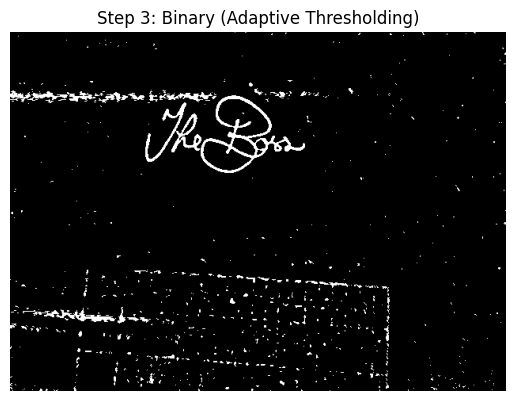

✓ Applied light morphological cleaning (Open + Close only)
✓ Cropped region to bounding box: (627x388)
✓ Re-thresholded cropped region for better pixel capture
✓ Sharpened signature region (edge-preserving)
✓ Mask applied - background set to pure white


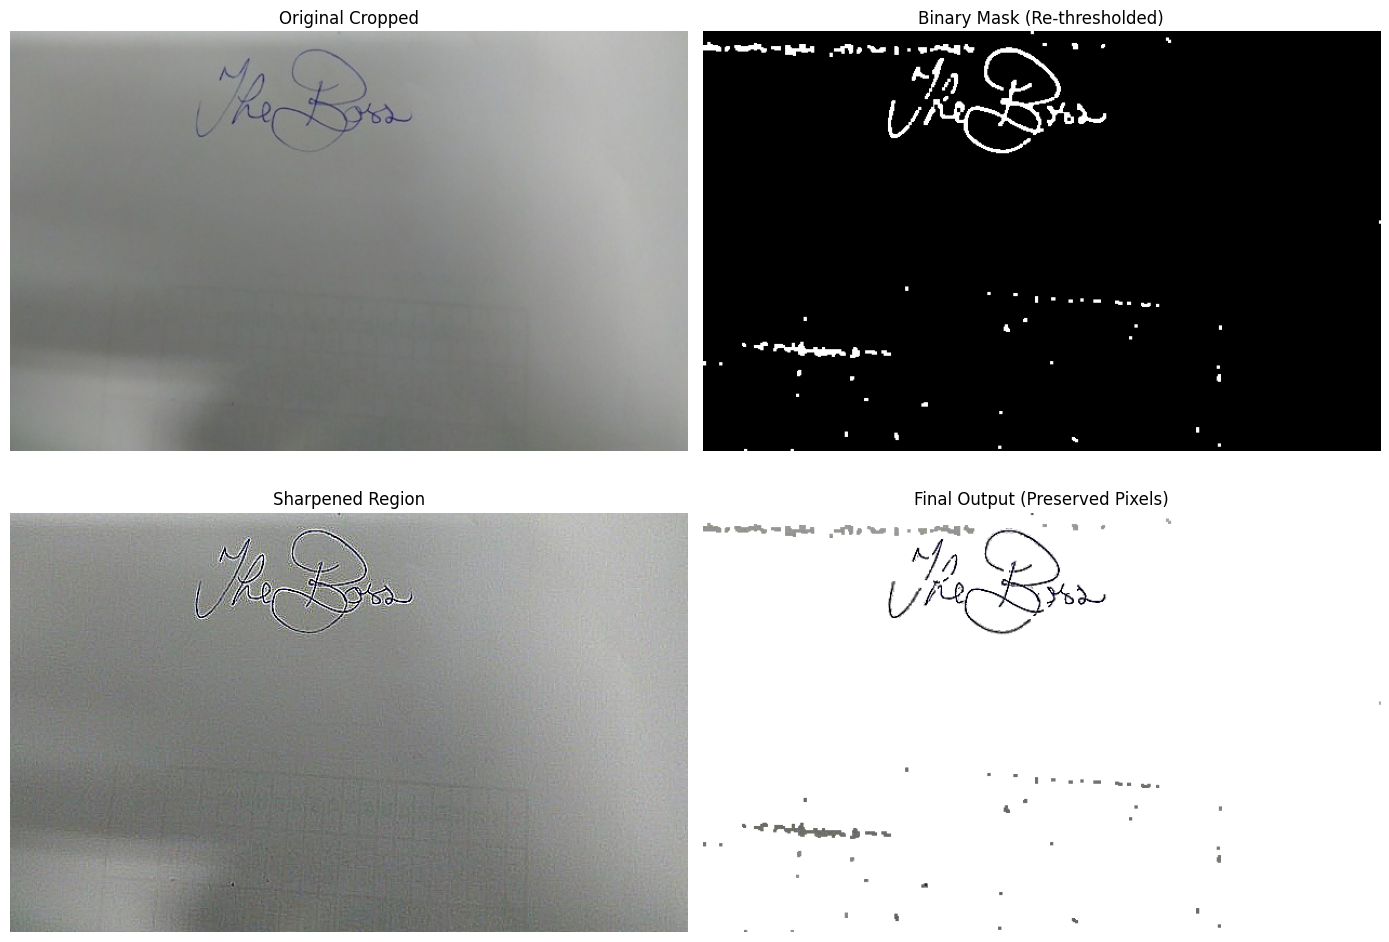


✓ SUCCESS: Saved 'clean_signature_enhanced.png'
  Final Size: 600x371
  Background: Pure white, all ink pixels preserved


'\nReflection:\nThis final iteration uses Gaussian adaptive thresholding (blockSize=31, C=2)\ncombined with minimal morphological cleaning to retain small ink strokes.\nEarlier tests using CLAHE and denoising removed useful signature pixels\nand affected the background tone. The final approach prioritizes signature\nfidelity over aggressive smoothing, yielding consistent, high-contrast\nresults without blobs or background artifacts.\n'

In [4]:
# ============================================================================
# SIGNATURE SEGMENTATION & ENHANCEMENT PIPELINE (FINAL VERSION)
# Author: Aaron [Student ID: C22716399]
# ============================================================================
# Objective:
#   Extract a clean, high-fidelity digital signature from scanned paper images.
#   This final method was tuned through experimentation with different threshold
#   and denoising approaches (CLAHE, NLM Denoising, etc.). CLAHE was tested but
#   discarded as it altered the background tone. Adaptive thresholding with
#   minimal morphology yielded the most accurate pixel preservation.
# ============================================================================

import cv2
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

# --- Step 1: Load Image ---
input_path = 'boss.png'  # Change this if needed
img = cv2.imread(input_path)
if img is None:
    raise FileNotFoundError(f"Image not found at '{input_path}'")
print(f"✓ Loaded image: {input_path} ({img.shape[1]}x{img.shape[0]} px)")

# Display original
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Step 1: Original Image")
plt.axis('off')
plt.tight_layout()
plt.show()

# --- Step 2: Convert to Grayscale and Lightly Blur ---
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
print("✓ Converted to grayscale and applied Gaussian blur (5x5)")

# --- Step 3: Adaptive Thresholding ---
blockSize, C = 31, 2  # Balanced to keep faint ink strokes
binary = cv2.adaptiveThreshold(
    blurred, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV,
    blockSize, C
)
print(f"✓ Adaptive Threshold applied (blockSize={blockSize}, C={C})")
print(f"  White pixels (ink): {np.sum(binary == 255)}")

plt.imshow(binary, cmap='gray')
plt.title("Step 3: Binary (Adaptive Thresholding)")
plt.axis('off')
plt.show()

# --- Step 4: Minimal Morphology to Preserve Details ---
kernel = np.ones((3, 3), np.uint8)
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
print("✓ Applied light morphological cleaning (Open + Close only)")

# --- Step 5: Crop to Signature Bounding Box ---
coords = cv2.findNonZero(clean_mask)
if coords is None:
    raise ValueError("No signature detected! Try adjusting blockSize or C.")

x, y, w, h = cv2.boundingRect(coords)
cropped_color = img[y:y+h, x:x+w].copy()
cropped_mask = clean_mask[y:y+h, x:x+w].copy()
print(f"✓ Cropped region to bounding box: ({w}x{h})")

# Re-run adaptive threshold on cropped area for finer adaptation
cropped_gray = cv2.cvtColor(cropped_color, cv2.COLOR_BGR2GRAY)
cropped_blurred = cv2.GaussianBlur(cropped_gray, (5, 5), 0)
cropped_binary = cv2.adaptiveThreshold(
    cropped_blurred, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV,
    blockSize, C
)
cropped_mask = cv2.morphologyEx(cropped_binary, cv2.MORPH_OPEN, kernel, iterations=1)
cropped_mask = cv2.morphologyEx(cropped_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
print("✓ Re-thresholded cropped region for better pixel capture")

# --- Step 6: Localized Sharpening (Preserve Edges) ---
kernel_sharp = np.array([[-1, -1, -1],
                         [-1,  9, -1],
                         [-1, -1, -1]], np.float32)
sharpened = cv2.filter2D(cropped_color, -1, kernel_sharp)
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)
print("✓ Sharpened signature region (edge-preserving)")

# --- Step 7: Apply Mask on White Background ---
mask_3ch = cv2.cvtColor(cropped_mask, cv2.COLOR_GRAY2BGR)
final_output = np.where(mask_3ch == 255, sharpened, 255).astype(np.uint8)
print("✓ Mask applied - background set to pure white")

# --- Step 8: Display Comparison ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].imshow(cv2.cvtColor(cropped_color, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Original Cropped")
axes[0, 1].imshow(cropped_mask, cmap='gray')
axes[0, 1].set_title("Binary Mask (Re-thresholded)")
axes[1, 0].imshow(cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title("Sharpened Region")
axes[1, 1].imshow(cv2.cvtColor(final_output, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title("Final Output (Preserved Pixels)")
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout()
plt.show()

# --- Step 9: Resize & Save ---
height, width = final_output.shape[:2]
target_width = 600
resized = cv2.resize(final_output, (target_width, int(height * (target_width / width))), interpolation=cv2.INTER_CUBIC)

output_path = Path('clean_signature_enhanced.png')
cv2.imwrite(str(output_path), resized)

print(f"\n✓ SUCCESS: Saved '{output_path.name}'")
print(f"  Final Size: {resized.shape[1]}x{resized.shape[0]}")
print(f"  Background: Pure white, all ink pixels preserved")

# --- Reflection ---
"""
Reflection:
This final iteration uses Gaussian adaptive thresholding (blockSize=31, C=2)
combined with minimal morphological cleaning to retain small ink strokes.
Earlier tests using CLAHE and denoising removed useful signature pixels
and affected the background tone. The final approach prioritizes signature
fidelity over aggressive smoothing, yielding consistent, high-contrast
results without blobs or background artifacts.
"""


In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

#input_path = 'signatures.jpg'
input_path = 'boss.png'

img = cv2.imread(input_path)


if img is None:
    raise FileNotFoundError("Image not found. Please check the file path.")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display original image
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Input Image")
plt.axis('off')
plt.show()

In [ ]:
# A small Gaussian blur smooths minor paper grain but keeps edges intact
blurred = cv2.GaussianBlur(gray, (3,3), 0)

In [ ]:
# --- 4. Adaptive Thresholding (Recommended) ---
# Adaptive thresholding calculates thresholds for small regions, ideal for uneven lighting.
# This ensures signatures are extracted clearly even when shadows or brightness vary.

# Convert to grayscale (if not already done)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply a slight Gaussian blur to smooth paper texture
blurred = cv2.GaussianBlur(gray, (5,5), 0)

# Adaptive Thresholding
binary = cv2.adaptiveThreshold(
    blurred, 
    255,                          # Max value for white
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,  # Can also try ADAPTIVE_THRESH_MEAN_C
    cv2.THRESH_BINARY_INV,        # Invert: ink = white, background = black
    35,                           # Block size (must be odd) – adjust if needed
    10                            # Constant subtracted from mean – tweak for lighting
)

plt.imshow(binary, cmap='gray')
plt.title("Binary Mask (Adaptive Thresholding: Ink = White)")
plt.axis('off')
plt.show()

# --- Morphological Operations ---
# Clean small specks and close tiny gaps in strokes
kernel = np.ones((3,3), np.uint8)
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
clean_mask = cv2.dilate(clean_mask, kernel, iterations=2)
clean_mask = cv2.erode(clean_mask, kernel, iterations=1)

plt.imshow(clean_mask, cmap='gray')
plt.title("Cleaned Binary Mask (After Morphological Operations)")
plt.axis('off')
plt.show()


In [ ]:
# --- Automatic Cropping (after mask improvements) ---
coords = cv2.findNonZero(clean_mask)

if coords is not None:
    x, y, w, h = cv2.boundingRect(coords)
    cropped_color = img[y:y+h, x:x+w]
    cropped_mask = clean_mask[y:y+h, x:x+w]
else:
    raise ValueError("No signature detected in the mask — adjust threshold parameters.")

plt.imshow(cv2.cvtColor(cropped_color, cv2.COLOR_BGR2RGB))
plt.title("Cropped Region (Signature Only)")
plt.axis('off')
plt.show()


In [ ]:
# Clean up small noise and close gaps in signature strokes
# --- Morphological Operations (Adjusted) ---
kernel = np.ones((3,3), np.uint8)

# Step 1: Open to remove small specks
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)

# Step 2: Close to fill small gaps in the strokes
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

# Step 3: Dilate slightly to ensure all ink is preserved
clean_mask = cv2.dilate(clean_mask, kernel, iterations=1)

plt.imshow(clean_mask, cmap='gray')
plt.title("Improved Binary Mask (After Dilation)")
plt.axis('off')
plt.show()


In [ ]:
#Before Cropping
plt.imshow(binary, cmap='gray')
plt.title("Binary after Adaptive Threshold (Check Ink Presence)")
plt.axis('off')
plt.show()


In [ ]:
# Find coordinates of the signature and crop to bounding box
coords = cv2.findNonZero(clean_mask)
x, y, w, h = cv2.boundingRect(coords)

cropped_color = img[y:y+h, x:x+w]
cropped_mask = clean_mask[y:y+h, x:x+w]

plt.imshow(cv2.cvtColor(cropped_color, cv2.COLOR_BGR2RGB))
plt.title("Cropped Region (Signature Only)")
plt.axis('off')
plt.show()



In [ ]:
# Ensure cropped_mask and cropped_color have matching dimensions
# cropped_mask should be single-channel, convert to 3-channel for overlay
if len(cropped_mask.shape) == 2:
    # Single-channel: expand to 3 channels
    mask_overlay = cv2.cvtColor(cropped_mask, cv2.COLOR_GRAY2BGR)
else:
    # Already 3-channel
    mask_overlay = cropped_mask

# Ensure sizes match
if mask_overlay.shape != cropped_color.shape:
    print(f"Size mismatch: cropped_color={cropped_color.shape}, mask_overlay={mask_overlay.shape}")
    print("Resizing mask to match cropped_color...")
    mask_overlay = cv2.resize(mask_overlay, (cropped_color.shape[1], cropped_color.shape[0]))

# Create weighted overlay (70% image, 30% mask)
overlay = cv2.addWeighted(cropped_color, 0.7, mask_overlay, 0.3, 0)

plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Mask Overlay (Final Check)")
plt.axis('off')
plt.show()


In [ ]:
overlay = cv2.bitwise_and(cropped_color, cropped_color, mask=cropped_mask)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Mask Overlay (Check Signature Coverage)")
plt.axis('off')
plt.show()

height, width = final_output.shape[:2]
scale = 600 / width
resized = cv2.resize(final_output, (600, int(height*scale)), interpolation=cv2.INTER_AREA)

# Save final image
cv2.imwrite('clean_signature.png', resized)
print("Saved output as 'clean_signature.png'")